In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

In [7]:
# 1. Khai báo số liệu trực tiếp trong code (dữ liệu từ Ví dụ 4.7 trang 88 SGK)
data_goc = np.array([176, 183, 185, 190, 191, 192, 201, 205, 214, 220])
# In ra bảng số liệu ban đầu
print("--- BẢNG SỐ LIỆU BAN ĐẦU (Ví dụ 4.7 trang 88 SGK) ---")
df_ban_dau = pd.DataFrame({'STT': np.arange(1, len(data_goc) + 1), 'Giá trị': data_goc})
print(df_ban_dau.to_string(index=False))
print("\n")

--- BẢNG SỐ LIỆU BAN ĐẦU (Ví dụ 4.7 trang 88 SGK) ---
 STT  Giá trị
   1      176
   2      183
   3      185
   4      190
   5      191
   6      192
   7      201
   8      205
   9      214
  10      220




In [8]:
# 2. Sắp xếp số liệu tăng dần
data_sap_xep = np.sort(data_goc)
# In ra bảng sau khi sắp xếp
print("--- BẢNG SỐ LIỆU SAU SẮP XẾP ---")
df_sap_xep = pd.DataFrame({'STT': np.arange(1, len(data_sap_xep) + 1), 'Giá trị tăng dần': data_sap_xep})
print(df_sap_xep.to_string(index=False))
print("\n")

--- BẢNG SỐ LIỆU SAU SẮP XẾP ---
 STT  Giá trị tăng dần
   1               176
   2               183
   3               185
   4               190
   5               191
   6               192
   7               201
   8               205
   9               214
  10               220




In [9]:
# 3. Tính toán các đại lượng đặc trưng
n = len(data_sap_xep)
mu = np.mean(data_sap_xep)
sigma = np.std(data_sap_xep, ddof=1) # ddof=1 cho độ lệch chuẩn mẫu

print(f"Kỳ vọng toán (Mean) : {mu:.2f}")
print(f"Độ lệch chuẩn (Std) : {sigma:.4f}\n")

# Tính toán các thông số
j = np.arange(1, n + 1)
p_j = (j - 0.5) / n
z_j = norm.ppf(p_j) # Trích xuất giá trị Z từ phân phối chuẩn tắc

# In bảng tính toán
print("--- BẢNG TÍNH TOÁN ---")
df = pd.DataFrame({
    'j': j,
    'x_j': data_sap_xep,
    'p_j = (j-0.5)/n': p_j,
    'z_j = Φ⁻¹(p_j)': z_j
})
# Định dạng in làm tròn 3 chữ số thập phân cho dễ nhìn
print(df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print("\n")

Kỳ vọng toán (Mean) : 195.70
Độ lệch chuẩn (Std) : 14.0321

--- BẢNG TÍNH TOÁN ---
 j  x_j  p_j = (j-0.5)/n  z_j = Φ⁻¹(p_j)
 1  176            0.050          -1.645
 2  183            0.150          -1.036
 3  185            0.250          -0.674
 4  190            0.350          -0.385
 5  191            0.450          -0.126
 6  192            0.550           0.126
 7  201            0.650           0.385
 8  205            0.750           0.674
 9  214            0.850           1.036
10  220            0.950           1.645




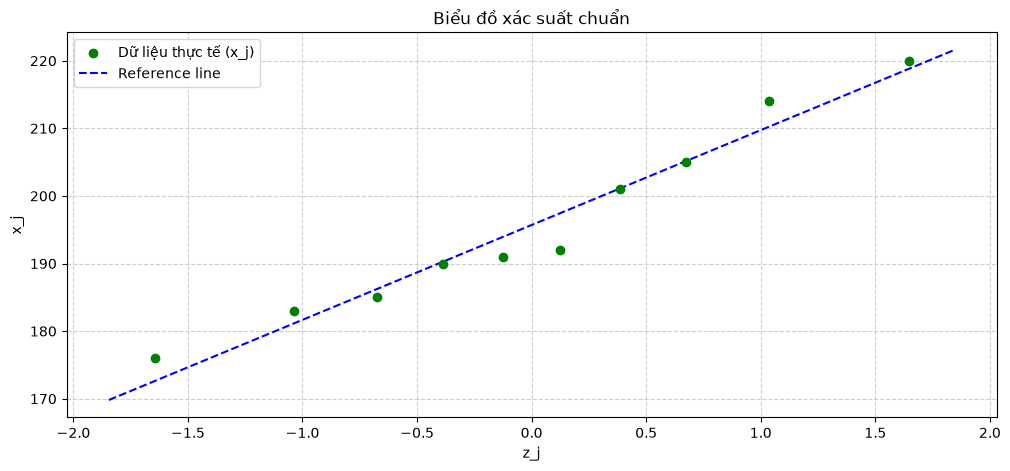

In [10]:
# 4. Vẽ biểu đồ thủ công
plt.figure(figsize=(12, 5))

# Vẽ các điểm dữ liệu thực tế
plt.scatter(z_j, data_sap_xep, color='green', zorder=5, label='Dữ liệu thực tế (x_j)')

# Vẽ đường thẳng tham chiếu: x = sigma*z + mu
z_line = np.linspace(min(z_j) - 0.2, max(z_j) + 0.2)
x_line = sigma * z_line + mu
plt.plot(z_line, x_line, color='blue', linestyle='--', label='Reference line')

plt.title('Biểu đồ xác suất chuẩn')
plt.xlabel('z_j'); plt.ylabel('x_j')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()